# Explainable AI: explaining a random forest with Anchors, SHAP, LIME and ELI5

**Problem.** A random forest can predict whether a prostate tumour is malignant (**M**) or benign (**B**) from eight measurements of the tumour, but it doesn't tell us *why* it made a prediction. In this notebook we train such a model and then use four explainable-AI (XAI) libraries to look inside it:
* **Anchors**: an if–then rule that is enough to "anchor" one prediction;
* **SHAP**: how much each feature pushed one prediction up or down (Shapley values);
* **LIME**: a simple linear model that imitates the forest around one patient;
* **ELI5**: the forest's feature importances and the feature contributions to one prediction.

In the last part we use the `xai` library to check a second dataset (heart failure) for imbalance, because a model trained on unbalanced data can be unfair to the groups that are under-represented.

**How to run.** Run the cells from top to bottom (Run → Run All Cells). The first code cell installs the libraries in your browser (about a minute the first time). The data files `Prostate_Cancer.csv` and `heart.csv` and the `wheels` folder are in the same folder as this notebook. Training the model and the SHAP kernel explainer take up to a minute each.

**Expected result.** A random forest with about 85 % cross-validated accuracy; an anchor rule for one patient with a precision above 0.9; SHAP plots in which *perimeter*, *compactness* and *area* matter most; LIME and ELI5 explanations that agree with SHAP; and bar charts that show how unbalanced the heart-failure data is before and after resampling.

Some cells print many `UserWarning: X does not have valid feature names` messages. They are harmless: the explainers pass plain NumPy arrays to a model that was trained on a pandas DataFrame.

**Sources.** This tutorial is based on:

* https://towardsdatascience.com/shap-shapley-additive-explanations-5a2a271ed9c3

* https://github.com/FernandoLpz/SHAP-Classification-example/blob/master/shap_demo.ipynb

* https://www.kaggle.com/code/vikumsw/explaining-random-forest-model-with-lime/notebook

* https://pypi.org/project/xai/


**Datasets.** *Prostate Cancer* (100 patients) by Sajid Saifi and *Heart Failure Prediction* (918 patients) by fedesoriano (Open Database License), both from Kaggle. Copies are in this folder.

## 0. Install the libraries
`optuna` (hyper-parameter tuning), `shap` and `eli5` are installed from PyPI. `lime` and `anchor-exp` are published on PyPI only as source code, which the browser can't install, so ready-built copies are in the `wheels` folder next to this notebook (`emfs:` means "a file in this notebook's folder"). `anchor-exp` and `xai` are installed without their dependencies: anchor-exp would pull in spaCy (needed only for text), and xai asks for pandas < 3 while the browser has pandas 3. Everything else they need is already available.

In [1]:
%pip install optuna shap eli5
%pip install emfs:wheels/lime-0.2.0.1-py3-none-any.whl
%pip install --no-deps emfs:wheels/anchor_exp-0.0.2.0-py3-none-any.whl xai

## 1. The model: a random forest tuned with Optuna
The `Classifier` class trains the model as soon as it is created. Optuna tries 10 combinations of three hyper-parameters (split criterion, number of trees, maximum depth). Each combination is scored by 3-fold cross-validation on the training set only, and the best one is used to train the final forest. The fixed seeds (`seed=42`, `random_state=42`) give the same results every time you run the notebook.

In [2]:
# import xgboost as xgb  # only needed for the XGBoost alternative below
import optuna
import numpy as np

from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestClassifier

class Classifier:

    def __init__(self, **kwargs) -> None:
        self.x_train = kwargs['x_train']
        self.x_test = kwargs['x_test']
        self.y_train = kwargs['y_train']
        self.y_test = kwargs['y_test']

        self._train()

        pass

    
    def _optimize(self, trial) -> np.ndarray:
    
        # Definition of search space
        criterion = trial.suggest_categorical('criterion', ['gini', 'entropy'])
        n_estimators = trial.suggest_int('n_estimators', 10, 500)
        max_depth = trial.suggest_int('max_depth', 2, 10)

        # Classifier definition (we tried XGBoost and Random Forest algorithms; the explanation process and output style are the same)
        model = RandomForestClassifier(n_estimators=n_estimators,
                                    max_depth=max_depth,
                                    criterion=criterion, 
                                    n_jobs=-1,
                                    random_state=42)
        #model = xgb.XGBClassifier(random_state=42)

        avg_accuracy = []

        # Definition of k-fold cross validation
        k_fold = KFold(n_splits=3)

        for train_idx, test_idx in k_fold.split(self.x_train.values, self.y_train.values):
            
            # Training fold
            x_train = self.x_train.values[train_idx]
            y_train = self.y_train.values[train_idx]
            
            # Testing fold
            x_test = self.x_train.values[test_idx]
            y_test = self.y_train.values[test_idx]

            # Training (on two folds)
            model.fit(x_train, y_train)

            # Save accuracy (on the third fold)
            avg_accuracy.append(model.score(x_test, y_test))
        
        return np.mean(avg_accuracy)


    def _train(self) -> None:
        
        # Hyperparameter Optimization
        study = optuna.create_study(direction='maximize',
                                    sampler=optuna.samplers.TPESampler(seed=42))  # seed: same trials every run
        study.optimize(self._optimize, n_trials=10)

        # Train with optimal parameters
        self.model = RandomForestClassifier(n_estimators=study.best_params['n_estimators'],
                                            criterion=study.best_params['criterion'],
                                            max_depth=study.best_params['max_depth'],
                                            random_state=42)
        
        self.model.fit(self.x_train, self.y_train)

## 2. The data
The `Data` class reads the CSV file, drops the `id` column, replaces spaces in the column names with underscores, encodes the diagnosis as numbers (**M = 0, B = 1**) and keeps 25 % of the patients aside as a test set.

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

class Data:

    def __init__(self, csv_path: str) -> None:
        self.csv_path = csv_path
        self.data = pd.read_csv(self.csv_path)

        self._transform()
        self._split()

        pass

    def _transform(self) -> None:
        self.data.drop(['id'], axis=1, inplace=True)  # the id is not a measurement
        self.data.columns = self.data.columns.str.replace(' ', '_')

        self.classes = {0: 'M', 1: 'B'}
        self.data['diagnosis_result'] = self.data['diagnosis_result'].map({'M': 0, 'B': 1})

    def _split(self) -> None:
        self.x_train, self.x_test, self.y_train, self.y_test = \
            train_test_split(self.data.drop(['diagnosis_result'], axis=1), self.data['diagnosis_result'], test_size=0.25, random_state=42)

    def __len__(self) -> int:
        return self.data.shape[0]

    def __str__(self) -> str:
        return f"Dataset with {self.data.shape[0]} samples and {self.data.shape[1] - 1} features"

    def __repr__(self) -> str:
        return f"Data({self.csv_path})"

Now we load the data and train the classifier. Optuna prints one line per trial with its cross-validated accuracy; the best value is about 0.85.

In [4]:
data = Data(csv_path='Prostate_Cancer.csv')
classifier = Classifier(x_train=data.x_train, x_test=data.x_test, y_train=data.y_train, y_test=data.y_test)

[I 2026-10-22 12:51:16,098] A new study created in memory with name: no-name-7703faed-9d72-49eb-b017-e129ebdfb041


[I 2026-10-22 12:51:18,365] Trial 0 finished with value: 0.84 and parameters: {'criterion': 'entropy', 'n_estimators': 369, 'max_depth': 7}. Best is trial 0 with value: 0.84.


[I 2026-10-22 12:51:18,610] Trial 1 finished with value: 0.8533333333333334 and parameters: {'criterion': 'gini', 'n_estimators': 38, 'max_depth': 9}. Best is trial 1 with value: 0.8533333333333334.


[I 2026-10-22 12:51:18,752] Trial 2 finished with value: 0.8533333333333334 and parameters: {'criterion': 'entropy', 'n_estimators': 20, 'max_depth': 10}. Best is trial 1 with value: 0.8533333333333334.


[I 2026-10-22 12:51:19,368] Trial 3 finished with value: 0.8533333333333334 and parameters: {'criterion': 'gini', 'n_estimators': 99, 'max_depth': 3}. Best is trial 1 with value: 0.8533333333333334.


[I 2026-10-22 12:51:20,530] Trial 4 finished with value: 0.8533333333333334 and parameters: {'criterion': 'entropy', 'n_estimators': 222, 'max_depth': 4}. Best is trial 1 with value: 0.8533333333333334.


[I 2026-10-22 12:51:21,357] Trial 5 finished with value: 0.84 and parameters: {'criterion': 'gini', 'n_estimators': 153, 'max_depth': 5}. Best is trial 1 with value: 0.8533333333333334.


[I 2026-10-22 12:51:21,955] Trial 6 finished with value: 0.8533333333333334 and parameters: {'criterion': 'entropy', 'n_estimators': 108, 'max_depth': 6}. Best is trial 1 with value: 0.8533333333333334.


[I 2026-10-22 12:51:23,551] Trial 7 finished with value: 0.8533333333333334 and parameters: {'criterion': 'gini', 'n_estimators': 308, 'max_depth': 3}. Best is trial 1 with value: 0.8533333333333334.


[I 2026-10-22 12:51:26,341] Trial 8 finished with value: 0.8533333333333334 and parameters: {'criterion': 'entropy', 'n_estimators': 484, 'max_depth': 9}. Best is trial 1 with value: 0.8533333333333334.


[I 2026-10-22 12:51:28,336] Trial 9 finished with value: 0.8533333333333334 and parameters: {'criterion': 'gini', 'n_estimators': 345, 'max_depth': 5}. Best is trial 1 with value: 0.8533333333333334.


## 3. Anchors
An **anchor** is an if–then rule on the features that is enough to fix the model's prediction for one patient: the search looks for a rule under which the model gives the same prediction at least 95 % of the time (`threshold=0.95` below). If no rule reaches that, it returns the most precise rule it found, so the precision printed below can be slightly lower. First we collect the class names (in the order of the labels: position 0 is M, position 1 is B) and the feature names, and look at the first training patients.

In [5]:
class_name = [data.classes[0], data.classes[1]]  # ['M', 'B']: list position = class label (0 = M, 1 = B)

In [6]:
features=list(data.x_train.columns)

In [7]:
features

['radius',
 'texture',
 'perimeter',
 'area',
 'smoothness',
 'compactness',
 'symmetry',
 'fractal_dimension']

In [8]:
data.x_train[:10]

,radius,texture,perimeter,area,smoothness,compactness,symmetry,fractal_dimension
15,22,19,97,659,0.114,0.160,0.230,0.071
40,24,16,86,563,0.082,0.060,0.178,0.056
96,22,14,78,451,0.105,0.071,0.190,0.066
9,25,11,84,476,0.119,0.240,0.203,0.082
72,21,12,114,929,0.107,0.183,0.193,0.065
11,17,15,104,781,0.097,0.129,0.184,0.061
47,20,14,86,535,0.116,0.123,0.213,0.068
85,14,13,121,1075,0.099,0.105,0.213,0.060
28,15,15,102,732,0.108,0.170,0.193,0.065
93,10,17,87,555,0.102,0.082,0.164,0.057


Create the anchor explainer. It needs the class names, the feature names and the training data (to learn the typical range of each feature).

In [9]:
from anchor import anchor_tabular

In [10]:
anchor_explainer = anchor_tabular.AnchorTabularExplainer(class_names=class_name,
                                                    feature_names=features,
                                                    train_data=data.x_train.to_numpy())

Predict the class of single patients. `predict` returns the label as a number (0 = M, 1 = B); the third cell turns it into the class name for patient `idx = 1`. Fixing NumPy's random seed makes the anchor search below repeatable.

In [11]:
classifier.model.predict(data.x_train.iloc[0].values.reshape(1,-1))

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


array([0], dtype=int64)

In [12]:
#classifier.model.predict_proba(data.x_train.iloc[0].reshape(1, -1)[0])

In [13]:
idx = 1
np.random.seed(1)
print('Prediction: ', anchor_explainer.class_names[classifier.model.predict(data.x_train.iloc[idx].values.reshape(1,-1))[0]])

Prediction:  M


/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Search for an anchor for this patient (`threshold=0.95`). **Precision** is how often the model keeps the same prediction when the rule holds; **coverage** is the share of patients the rule applies to. A rule with more conditions is usually more precise but covers fewer patients.

In [14]:
exp = anchor_explainer.explain_instance(data.x_train.iloc[idx].values, classifier.model.predict, threshold=0.95)

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:26

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:26

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:26

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:26

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:26

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:26

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:26

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [15]:
print('Anchor: %s' % (' AND '.join(exp.names())))
print('Precision: %.2f' % exp.precision())
print('Coverage: %.2f' % exp.coverage())

Anchor: perimeter > 78.50 AND 0.18 < symmetry <= 0.21 AND area > 461.00 AND texture > 14.00 AND compactness <= 0.15
Precision: 0.93
Coverage: 0.16


## 4. SHAP
SHAP gives every feature a **Shapley value**: how much it moved this prediction away from the model's average prediction (the *base value*). Positive values push towards class B, negative values towards class M, and together they add up to the difference between the prediction and the base value. `TreeExplainer` computes them exactly and quickly for tree models.

In [16]:
import shap

In [17]:
shap_explainer = shap.TreeExplainer(classifier.model)

First a patient from class B (label 1); the model gives this patient a probability of about 0.95 of being benign. The force plot shows the features that push the prediction up (red) and down (blue) from the base value, and the array lists the SHAP values for class B in the order of the features (radius, texture, perimeter, …).

In [18]:
positive_sample = data.x_train[data.y_train == 1].iloc[0]  # first training patient with class 1 (B)
positive_class = data.y_train[data.y_train == 1].iloc[0]

In [19]:
classifier.model.predict_proba(positive_sample.values.reshape(1,-1))

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


array([[0.05263158, 0.94736842]])

In [20]:
shap_values_positive = shap_explainer.shap_values(positive_sample)

In [21]:
shap.initjs()
shap.force_plot(shap_explainer.expected_value[1], shap_values_positive[:, 1], positive_sample)

In [22]:
shap_values_positive[:, 1]

array([ 0.02102856,  0.00565138,  0.21378147,  0.10723418,  0.01181764,
        0.16336098, -0.01371733,  0.01259751])

The same for a patient from class M (label 0): now most SHAP values for class B are negative, which pushes the prediction towards M.

In [23]:
negative_sample = data.x_train[data.y_train == 0].iloc[0]  # first training patient with class 0 (M)
negative_class = data.y_train[data.y_train == 0].iloc[0]

In [24]:
classifier.model.predict_proba(negative_sample.values.reshape(1,-1))

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


array([[0.94736842, 0.05263158]])

In [25]:
shap_values_negative = shap_explainer.shap_values(negative_sample)

In [26]:
shap.initjs()
shap.force_plot(shap_explainer.expected_value[1], shap_values_negative[:, 1], negative_sample)

In [27]:
shap_values_negative[:, 1]

array([ 0.00376633, -0.02283465, -0.16457727, -0.11549912, -0.00033871,
       -0.07490917, -0.00318052,  0.00459067])

### SHAP for all training patients
The summary (beeswarm) plot shows one dot per patient and feature: its position is the SHAP value for class B and its colour is the feature value (red = high). The bar plot shows the mean absolute SHAP value of each feature for each class, i.e. the overall feature importance.

In [28]:
shap_tree_explainer = shap.TreeExplainer(classifier.model)

In [29]:
shap_values = shap_tree_explainer.shap_values(data.x_train)

/tmp/ipykernel_3187/28859460.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values[:, :, 1], data.x_train)


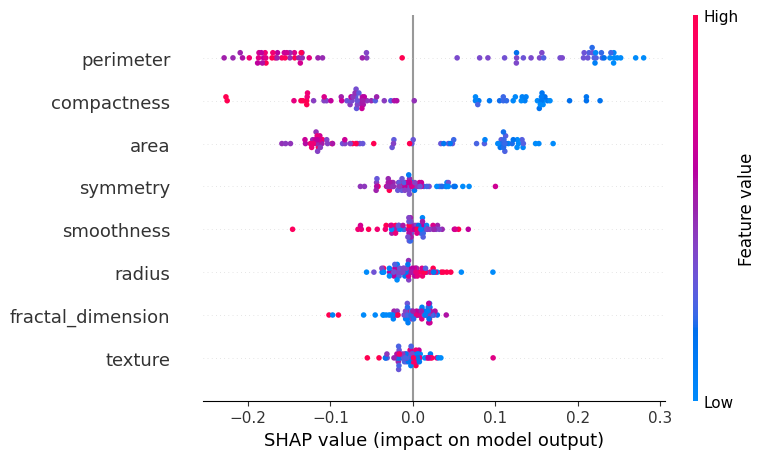

In [30]:
shap.summary_plot(shap_values[:, :, 1], data.x_train)

/tmp/ipykernel_3187/4141955597.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot([shap_values[:, :, 0], shap_values[:, :, 1]], data.x_train, plot_type="bar", class_names=class_name)


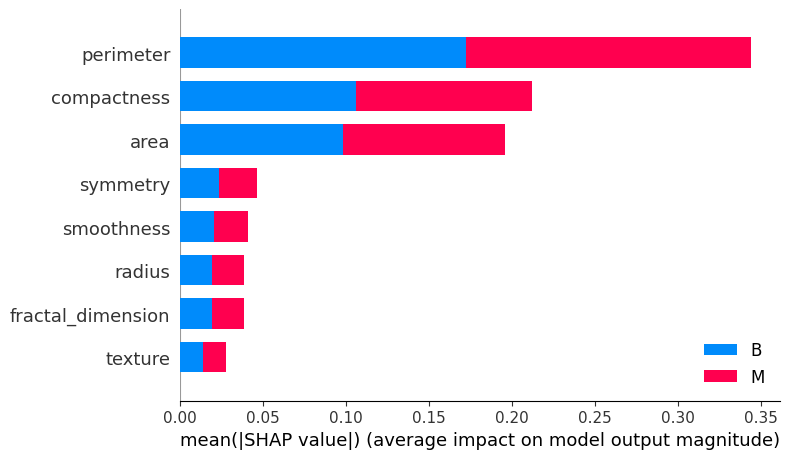

In [31]:
shap.summary_plot([shap_values[:, :, 0], shap_values[:, :, 1]], data.x_train, plot_type="bar", class_names=class_name)

### Kernel SHAP
`KernelExplainer` works with **any** model, because it only calls `predict_proba` on many modified copies of a patient. It is slower and approximate, but its explanations of training patients 0 and 3 should look similar to those of the tree explainer.

In [32]:
# Explainer
shap_kernel_explainer = shap.KernelExplainer(classifier.model.predict_proba, data.x_train)

In [33]:
# Shapley values for one specific patient
shap_values = shap_kernel_explainer.shap_values(data.x_train.iloc[0])
shap.force_plot(shap_kernel_explainer.expected_value[1], shap_values[:, 1], data.x_train.iloc[0])

In [34]:
# Shapley values for one specific patient
shap_values = shap_kernel_explainer.shap_values(data.x_train.iloc[3])
shap.force_plot(shap_kernel_explainer.expected_value[1], shap_values[:, 1], data.x_train.iloc[3])

## 5. LIME
LIME explains one prediction by creating many slightly changed copies of the patient, asking the forest for their probabilities, and fitting a simple **linear model** to these answers, weighted by how close each copy is to the patient. The weights of that linear model are the explanation. `kernel_width` sets how local "close" is. (`HTML` and `display` show LIME's interactive result in the notebook.)

In [35]:
import lime
import lime.lime_tabular
from IPython.display import HTML, display

In [36]:
predict_fn_rf = lambda x: classifier.model.predict_proba(x).astype(float)
X = data.x_train.values
lime_explainer = lime.lime_tabular.LimeTabularExplainer(X,feature_names = data.x_train.columns,class_names=class_name,kernel_width=5,
                                                   random_state=42)

We explain three test patients. Each result shows the predicted probabilities of M and B, the conditions on the features that support each class with their weights, and the patient's feature values.

In [37]:
data.x_test.iloc[0]

radius                 20.000
texture                14.000
perimeter             129.000
area                 1132.000
smoothness              0.122
compactness             0.179
symmetry                0.163
fractal_dimension       0.072
Name: 83, dtype: float64

In [38]:
chosen_instance = data.x_test.iloc[0]
exp = lime_explainer.explain_instance(chosen_instance.values, predict_fn_rf,num_features=8)
display(HTML(exp.as_html(show_all=False)))

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [39]:
chosen_instance = data.x_test.iloc[1]
exp = lime_explainer.explain_instance(chosen_instance.values, predict_fn_rf,num_features=8)
display(HTML(exp.as_html(show_all=False)))

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [40]:
chosen_instance = data.x_test.iloc[4]
exp = lime_explainer.explain_instance(chosen_instance.values, predict_fn_rf,num_features=8)
display(HTML(exp.as_html(show_all=False)))

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


## 6. ELI5
ELI5 ("explain like I'm 5") shows the forest's overall **feature importances** and, for one patient, how much each feature contributed to the predicted probability along the decision paths of the trees. We pass `feature_names` so that ELI5 shows the column names (listed below) instead of `x0` … `x7`.

In [41]:
import eli5

In [42]:
#data.x_test

In [43]:
features=data.x_test.columns

In [44]:
features = pd.DataFrame(features)

In [45]:
features

,0
0,radius
1,texture
2,perimeter
3,area
4,smoothness
5,compactness
6,symmetry
7,fractal_dimension


In [46]:
eli5.explain_weights(classifier.model, feature_names=list(data.x_train.columns))

Weight,Feature
0.3231 ± 0.5522,perimeter
0.1998 ± 0.4389,compactness
0.1895 ± 0.4937,area
0.0854 ± 0.2214,symmetry
0.0691 ± 0.1432,smoothness
0.0601 ± 0.1087,fractal_dimension
0.0464 ± 0.1101,radius
0.0266 ± 0.0651,texture


In [47]:
eli5.explain_prediction(classifier.model, data.x_test.head(1),
                        feature_names=list(data.x_train.columns))

/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeClassifier 

Explanation(estimator='RandomForestClassifier(max_depth=9, n_estimators=38, random_state=42)', description='\nFeatures with largest coefficients.\n\nFeature weights are calculated by following decision paths in trees\nof an ensemble (or a single tree for DecisionTreeClassifier).\nEach node of the tree has an output score, and contribution of a feature\non the decision path is how much the score changes from parent to child.\nWeights of all features sum to the output score or proba of the estimator.\n\nCaveats:\n1. Feature weights just show if the feature contributed positively or\n   negatively to the final score, and does not show how increasing or\n   decreasing the feature value will change the prediction.\n2. In some cases, feature weight can be close to zero for an important feature.\n   For example, in a single tree that computes XOR function, the feature at the\n   top of the tree will have zero weight because expected scores for both\n   branches are equal, so decision at the top feature does not change the\n   expected score. For an ensemble predicting XOR functions it might not be\n   a problem, but it is not reliable if most trees happen to choose the same\n   feature at the top.\n', error=None, method='decision path', is_regression=False, targets=[TargetExplanation(target=np.int64(0), feature_weights=FeatureWeights(pos=[FeatureWeight(feature='<BIAS>', weight=np.float64(0.5743859649122807), std=None, value=np.float64(1.0)), FeatureWeight(feature='perimeter', weight=np.float64(0.18334652596311618), std=None, value=np.float64(129.0)), FeatureWeight(feature='compactness', weight=np.float64(0.1272319847727761), std=None, value=np.float64(0.179)), FeatureWeight(feature='area', weight=np.float64(0.12259664478713983), std=None, value=np.float64(1132.0)), FeatureWeight(feature='texture', weight=np.float64(0.009240467182082034), std=None, value=np.float64(14.0)), FeatureWeight(feature='smoothness', weight=np.float64(0.008962026932610927), std=None, value=np.float64(0.122))], neg=[FeatureWeight(feature='symmetry', weight=np.float64(-0.06164991938481797), std=None, value=np.float64(0.163)), FeatureWeight(feature='fractal_dimension', weight=np.float64(-0.013350353495679498), std=None, value=np.float64(0.072)), FeatureWeight(feature='radius', weight=np.float64(-0.003394920616876799), std=None, value=np.float64(20.0))], pos_remaining=np.int64(0), neg_remaining=np.int64(0)), proba=np.float64(0.9473684210526315), score=None, weighted_spans=None, heatmap=None)], feature_importances=None, decision_tree=None, highlight_spaces=None, transition_features=None, image=None)

In [48]:
#model=LogisticRegression(max_iter=1000)
#model.fit(data.x_train,data.y_train)

In [49]:
#eli5.explain_prediction(model, data.x_test.head(1))

## 7. Checking data for imbalance with `xai`
A second dataset: 918 patients from the Heart Failure Prediction data, with the target `HeartDisease` (1 = heart disease). Before training a model on such data, we check how balanced it is.

In [50]:
#import xai.data
#df = xai.data.load_census()
#df.head()
#https://pypi.org/project/xai/

import pandas as pd

df = pd.read_csv('heart.csv')

In [51]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [52]:
import xai

`imbalance_plot` counts the patients in each category of one column, or in each combination of two columns. Look for groups that are much smaller than the others (for example women, and women with exercise-induced angina).

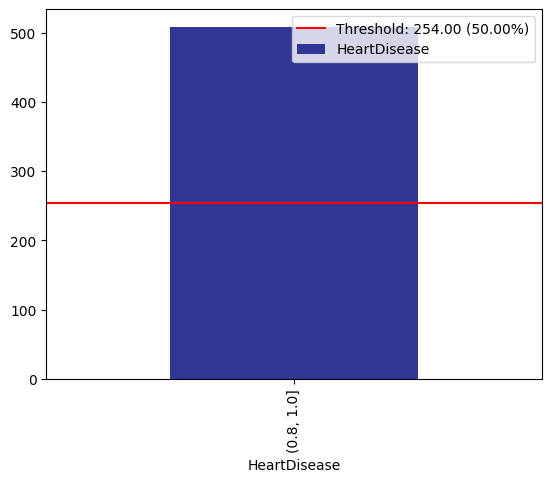

In [53]:
im= xai.imbalance_plot(df, "HeartDisease")

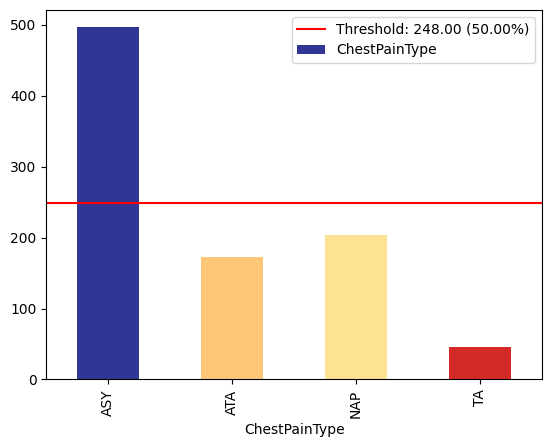

In [54]:
im= xai.imbalance_plot(df, "ChestPainType")

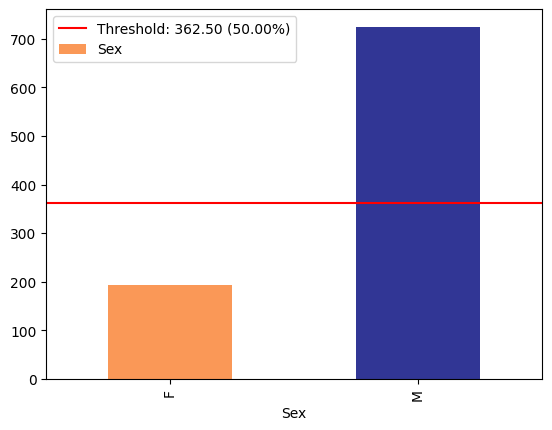

In [55]:
im= xai.imbalance_plot(df, "Sex")

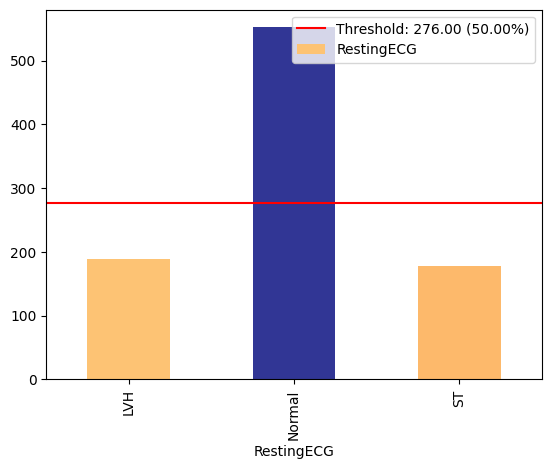

In [56]:
im= xai.imbalance_plot(df, "RestingECG")

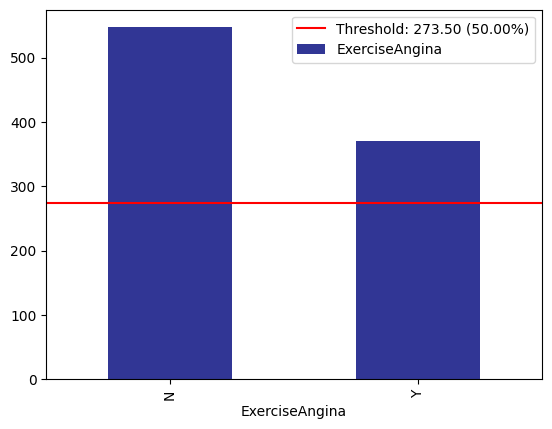

In [57]:
im= xai.imbalance_plot(df, "ExerciseAngina")

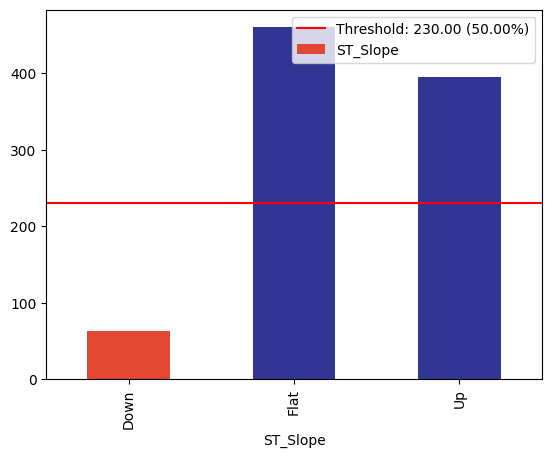

In [58]:
im= xai.imbalance_plot(df, "ST_Slope")

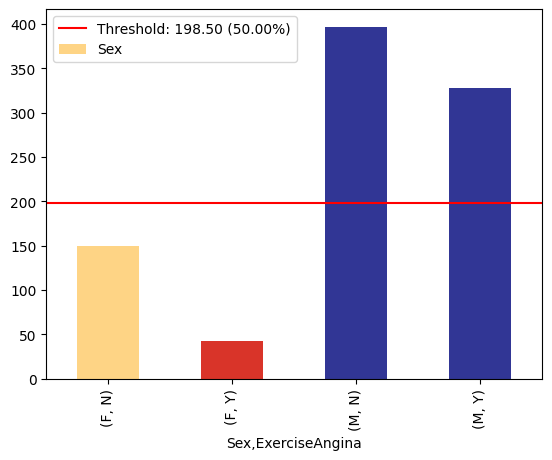

In [59]:
im = xai.imbalance_plot(df, "Sex", "ExerciseAngina")

`correlations` shows how strongly each pair of columns is related (categorical columns are converted to numbers first).

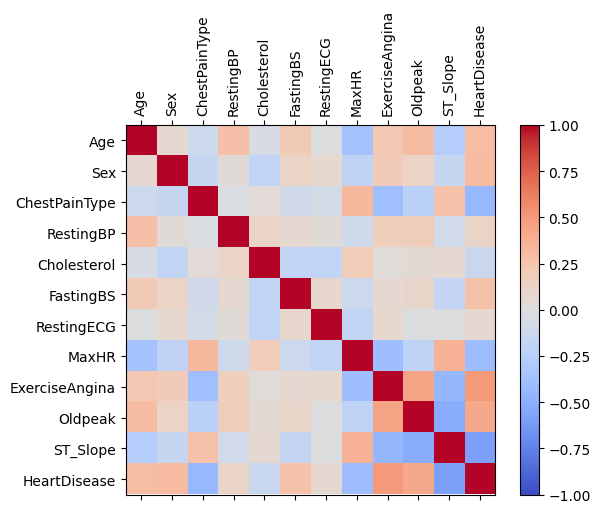

In [60]:
_ = xai.correlations(df, include_categorical=True, plot_type="matrix")

### Balancing the data
To give the small (Sex, ExerciseAngina) groups more weight, we **upsample** them: patients from a small group are drawn again at random (with replacement) until the group has 80 % of the size of the largest group. The `xai` library has a `balance()` function for this, but it doesn't work with pandas 3 (the browser's version), so the second cell does the same with pandas and plots the result. The balanced data has 1,359 rows.

In [61]:
categorical_cols = ["Sex", "ChestPainType", "RestingECG","ExerciseAngina","ST_Slope"]

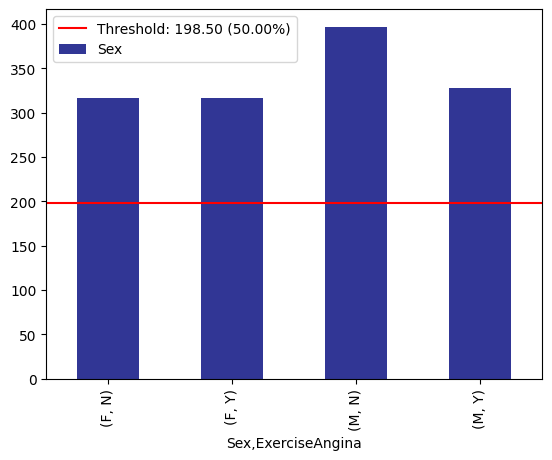

In [62]:
# xai.balance() needs pandas < 3, but the browser has pandas 3, so we do the same upsampling with pandas:
# every (Sex, ExerciseAngina) group smaller than 80% of the largest group is resampled up to that size.
np.random.seed(0)  # makes the random resampling below repeatable
groups = df.groupby(["Sex", "ExerciseAngina"])
target_size = int(0.8 * groups.size().max())
bal_df = pd.concat([g.sample(target_size, replace=True) if len(g) < target_size else g
                    for _, g in groups]).reset_index(drop=True)
_ = xai.imbalance_plot(bal_df, "Sex", "ExerciseAngina", categorical_cols=categorical_cols)

In [63]:
len(bal_df)

1359

### A balanced train/test split
`balanced_train_test_split` puts 300 patients from every combination of the target and `Sex` into the test set, so that both sexes and both outcomes are tested equally; the remaining patients form the training set. Groups with fewer than 300 patients are sampled with replacement, so some patients are picked twice and the test set ends up with 954 different patients. `train_idx` and `test_idx` are True/False masks over all rows of `bal_df`, so `len(train_idx)` is the number of rows (1,359), not the size of the training set.

In [64]:
x=bal_df.drop('HeartDisease', axis=1)

In [65]:
y=bal_df['HeartDisease']

In [66]:
# Balanced train-test split with minimum 300 examples of 
#     the cross of the target y and the column gender
x_train, y_train, x_test, y_test, train_idx, test_idx = \
    xai.balanced_train_test_split(
            x, y, "Sex", 
            min_per_group=300,
            max_per_group=300,
            categorical_cols=categorical_cols)

In [67]:
len(train_idx)

1359

In [68]:
x_train_display = bal_df[train_idx]

In [69]:
x_test_display = bal_df[test_idx]


In [70]:
print("Total number of examples: ", x_test.shape[0])

Total number of examples:  954


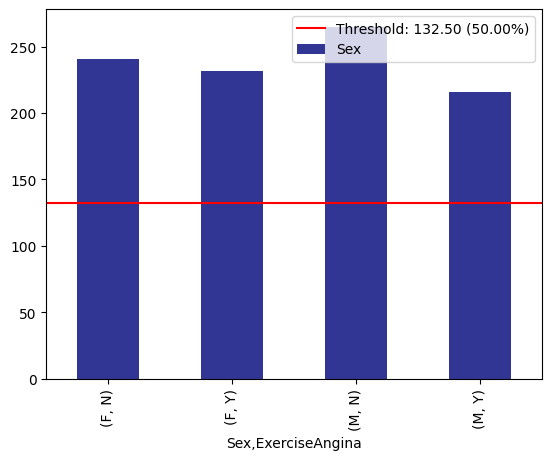

In [71]:
df_test = x_test_display.copy()
df_test["HeartDisease"] = y_test

_= xai.imbalance_plot(df_test, "Sex", "ExerciseAngina", categorical_cols=categorical_cols)

## What do you notice?
1. Do SHAP (bar plot), LIME and ELI5 agree on which features matter most for this model?
2. The anchor for patient 1 has several conditions but a coverage of only about 0.16. What does that tell you about this patient?
3. In the balanced split, how many patients are left for training, and is that a sensible split?

<details>
<summary>Answers</summary>

1. Yes. *Perimeter* is the most important feature in all three: it has the largest bar in the SHAP plot, it is the first condition in all three LIME explanations, and it has the largest ELI5 weight (about 0.32). *Compactness* and *area* come next. Different methods agreeing makes the explanation more trustworthy.
2. Only about 16 % of the patients satisfy the rule, so this patient lies in a fairly unusual region of the data: the model needs several conditions together before it is sure of the prediction. Precision tells us how reliable the rule is; coverage tells us how general it is.
3. Only 405 of the 1,359 rows (about 30 %) are left for training, because the test set takes 300 patients from each of the four groups. The test set is balanced, but it is much larger than the training set; with this little data you would usually choose a smaller `min_per_group`/`max_per_group` (for example 50) so that most patients are used for training.
</details>